In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [3]:
#dataset
layers = tf.keras.layers
keras.utils.set_random_seed(42)
df = pd.read_csv("energy_consumption.csv")
df.head()

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,01-01-2024 00:00,0.457786,0.469524,0.396368,0.445441,0.692057,0
1,01-01-2024 00:30,0.351956,0.465545,0.451184,0.458729,0.539874,0
2,01-01-2024 01:00,0.482948,0.285415,0.408289,0.470360,0.614724,0
3,01-01-2024 01:30,0.628838,0.482095,0.512308,0.576241,0.757044,0
4,01-01-2024 02:00,0.335974,0.624741,0.672021,0.373004,0.673981,0


In [4]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"],format="%d-%m-%Y %H:%M")
df = df.sort_values("Timestamp").reset_index(drop=True)
FEATURES = ["Electricity_Consumed", "Temperature", "Humidity", "Wind_Speed", "Avg_Past_Consumption"]
N_FEATURES = len(FEATURES)
df[FEATURES] = df[FEATURES].interpolate().bfill().ffill()   

In [6]:
#split
split = int(len(df) * 0.7)                                                
train_rows, test_rows = df.iloc[:split], df.iloc[split:]
scaler = MinMaxScaler().fit(train_rows.loc[train_rows.Anomaly_Label == 0, FEATURES]) 

In [8]:
#window <- extra thing
def make_windows(rows):
    data, lab = scaler.transform(rows[FEATURES]), rows["Anomaly_Label"].values
    n = len(data) - 10 + 1
    W = np.array([data[i:i + 10] for i in range(n)], dtype="float32")            # (n, 10, 5)
    y = np.array([lab[i:i + 10].max() for i in range(n)])                        # window is anomalous if ANY step is
    return W, y
Wtrall, ytr = make_windows(train_rows)
Xtes, yte = make_windows(test_rows)
Xtrn = Wtrall[ytr == 0]   

print(Xtrn.shape, Xtes.shape, yte.sum(),len(yte))

(2463, 10, 5) (1491, 10, 5) 436 1491


In [9]:
#layers
inp = keras.Input(shape=(10,5))
x = layers.LSTM(32)(inp)
x = layers.RepeatVector(10)(x)
x = layers.LSTM(32,return_sequences=True)(x)
out = layers.TimeDistributed(layers.Dense(5))(x)
ae = keras.Model(inp,out)
ae.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 10, 5)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 32)                  │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
ae.compile(optimizer="adam",loss="mse",metrics=["mae"])
stop = keras.callbacks.EarlyStopping(monitor="val_loss",patience=4,restore_best_weights=True)
hist = ae.fit(Xtrn,Xtrn,epochs=30,batch_size=64,validation_split=0.1,callbacks=[stop])

Epoch 1/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.1699 - mae: 0.3594 - val_loss: 0.0458 - val_mae: 0.1678
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0412 - mae: 0.1595 - val_loss: 0.0339 - val_mae: 0.1447
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0309 - mae: 0.1385 - val_loss: 0.0270 - val_mae: 0.1300
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0251 - mae: 0.1254 - val_loss: 0.0241 - val_mae: 0.1222
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0225 - mae: 0.1183 - val_loss: 0.0228 - val_mae: 0.1180
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0214 - mae: 0.1146 - val_loss: 0.0225 - val_mae: 0.1172
Epoch 7/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0211 - mae: 0.1138 - val_loss: 0.0223 - val_mae: 0.1166
Epoch 8/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0209 - mae: 0.1133 - val_loss: 0.0221 - val_mae: 0.1161
Epoch 9/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0207 - mae:

In [11]:
#reconstruction error
err_train = np.mean((Xtrn - ae.predict(Xtrn))**2,axis=(1,2))
err_test = np.mean((Xtes - ae.predict(Xtes))**2,axis=(1,2))
threshold = np.percentile(err_train,95)
pred = (err_test > threshold).astype(int)
print(threshold, pred.sum(),len(pred))

77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
0.024509936571121216 169 1491


In [12]:
#evaluate
print(classification_report(yte,pred,target_names=["normal","anomaly"],digits=3))
print(confusion_matrix(yte,pred))
print(round(roc_auc_score(yte,err_test),4))

              precision    recall  f1-score   support

      normal      0.746     0.935     0.830      1055
     anomaly      0.592     0.229     0.331       436

    accuracy                          0.728      1491
   macro avg      0.669     0.582     0.580      1491
weighted avg      0.701     0.728     0.684      1491

[[986  69]
 [336 100]]
0.6889


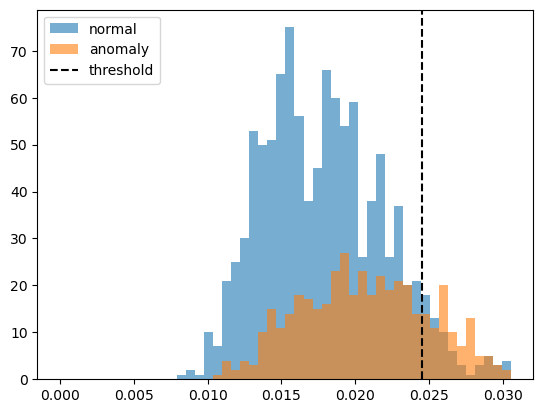

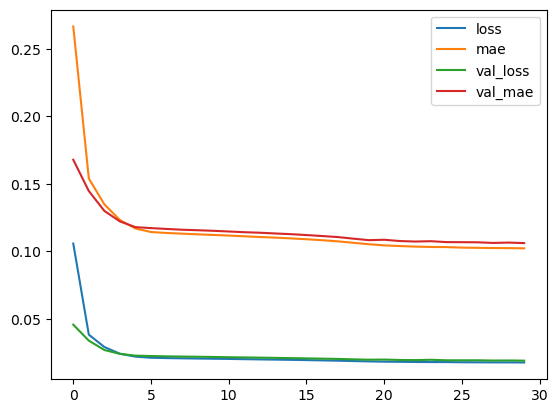

In [13]:
#plot
for k in (0,1):
    plt.hist(err_test[yte==k],50,range=(0,np.percentile(err_test,99)),alpha=0.6,label=["normal","anomaly"][k])
plt.axvline(threshold,color="k",ls="--",label="threshold")
plt.legend()
pd.DataFrame(hist.history).plot();
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


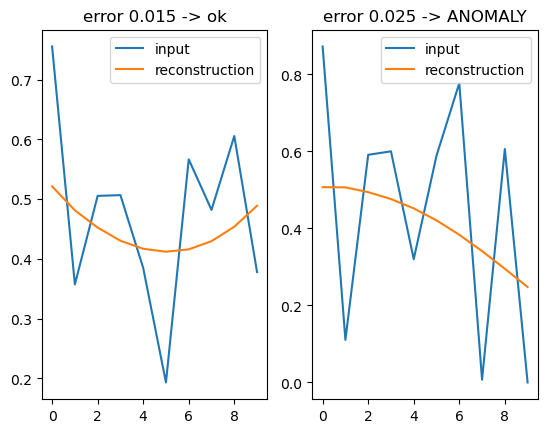

In [14]:
#one example
i = np.where(yte == 0)[0][0]                       # first normal window
j = np.where((yte == 1) & (pred == 1))[0][0]       # first anomalous window the model caught
for n, k in enumerate((i, j)):
    plt.subplot(1, 2, n+1); plt.plot(Xtes[k,:,0], label="input"); plt.plot(ae.predict(Xtes[k:k+1])[0,:,0], label="reconstruction")
    plt.title(f"error {err_test[k]:.3f} -> {'ANOMALY' if pred[k] else 'ok'}"); plt.legend()
plt.show()

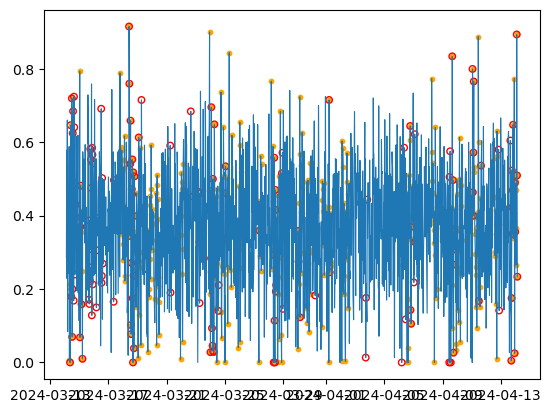

In [15]:
t = test_rows["Timestamp"].values[9:]; c = test_rows["Electricity_Consumed"].values[9:]   # one point per window (its last row)
plt.plot(t, c, lw=.8)
plt.scatter(t[yte == 1], c[yte == 1], s=10, c="orange")                          # true anomalies
plt.scatter(t[pred == 1], c[pred == 1], s=22, facecolors="none", edgecolors="red")  # flagged by the model
plt.show()